# Diffusion Policies for Reaching

Learn short actions for a simulated tabletop point moving towards a goal from offline demonstrations.

A neural network predicts clean action chunks from noisy chunks, a diffusion timestep and the vector to the goal. A deterministic DDIM-style reverse schedule samples six actions. The robot executes two actions before replanning. This state-conditioned exercise isolates the action diffusion and receding-horizon components of Diffusion Policy.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

import torch
from reaching import fit_policy, evaluate

## Train on generated demonstrations

The deterministic demonstrator removes one quarter of the remaining displacement per tick. The network receives the state displacement and a noisy action chunk. All network parameters are fitted from scratch.

In [2]:
kind = "diffusion"
model, alpha, losses = fit_policy(kind, seed=31, steps=1250)
print(
    "Gradient updates",
    len(losses),
    "| mean objective, first and last 100",
    np.round([losses[:100].mean(), losses[-100:].mean()], 5),
)

Gradient updates 1250 | mean objective, first and last 100 [8.266e-02 4.000e-05]


## Evaluate closed-loop reaching

Use 60 new start-goal pairs and fresh sampling noise. Report one-chunk action RMSE, terminal distance, success within 8 cm and the initial-distance baseline.

Action RMSE 0.0006 m/tick | mean distance before 0.757 m | after 0.024 m
Within 8 cm: 60 of 60


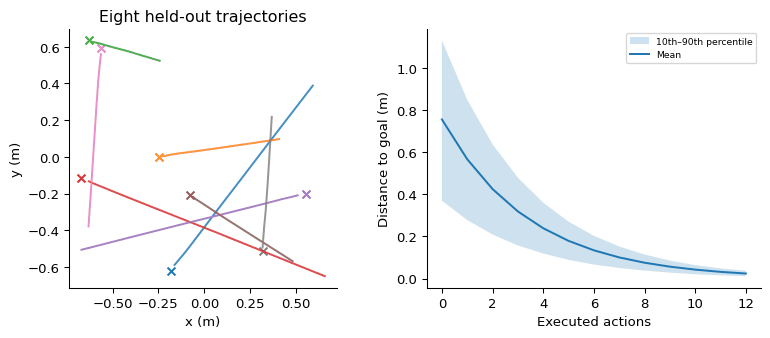

In [3]:
paths, goals, chunk_error = evaluate(model, alpha, kind, seed=197)
distance = np.linalg.norm(paths - goals[None, :, :], axis=2)
success = np.mean(distance[-1] < 0.08)
print(
    f"Action RMSE {chunk_error:.4f} m/tick | mean distance before {distance[0].mean():.3f} m | after {distance[-1].mean():.3f} m"
)
print(f"Within 8 cm: {int((distance[-1]<.08).sum())} of {len(goals)}")
assert distance[-1].mean() < 0.35 * distance[0].mean()
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.45), constrained_layout=True)
for i in range(8):
    line = a.plot(*paths[:, i, :].T, alpha=0.82)[0]
    a.scatter(*goals[i], marker="x", color=line.get_color())
a.set(aspect="equal", xlabel="x (m)", ylabel="y (m)", title="Eight held-out trajectories")
steps = np.arange(len(distance))
b.fill_between(
    steps, *np.quantile(distance, [0.1, 0.9], axis=1), alpha=0.22, label="10th–90th percentile"
)
b.plot(steps, distance.mean(1), label="Mean")
b.set(xlabel="Executed actions", ylabel="Distance to goal (m)")
b.legend(fontsize=7)
plt.show()

## Interpreting the result

This is a unimodal task with a known analytic expert. The result checks conditional generation and feedback during rollout. It does not measure physical robot performance or the ability to model multimodal demonstrations.

## Exercise

Execute all six actions before replanning and compare terminal error across the same held-out starts.

## References

[Chi et al., Diffusion Policy (2023)](https://diffusion-policy.cs.columbia.edu/)

[Song, Meng and Ermon, Denoising Diffusion Implicit Models](https://arxiv.org/abs/2010.02502)